# Predicting Credit Card Default with Statistical Machine Learning Models

**Dataset:** Default of Credit Card Clients, UCI Machine Learning Repository [1]

## 1. Introduction

A lender needs to know which clients are likely to miss their next payment. This notebook
predicts whether a credit card client in Taiwan **defaulted on their October 2005 payment**,
using six months of billing and repayment history (April to September 2005) [1].

Three statistical models are trained on an 80/20 train/test split and compared. They serve as a
baseline for the neural models later in the course: a more complex model has to beat them by
enough to justify its cost.

### Data

To run the notebook: install with `pip install ucimlrepo` (removed below since installed locally already)

The data is loaded straight from the UCI Machine Learning Repository through its Python API,
`ucimlrepo`. The API returns generic column names
(`X1` to `X23`), so they are renamed from UCI's own variable descriptions.

In [21]:
import random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

SEED = 20
random.seed(SEED)                     # for reproducibility of random operations
np.random.seed(SEED)                  # numpy randomness (train_test_split also gets random_state)

uci = fetch_ucirepo(id=350)                                         
names = dict(zip(uci.variables["name"], uci.variables["description"]))   # replacing old column names with the correct descriptive ones provided on UCI's repo
X_raw = uci.data.features.rename(columns=names)                     # setting our x & y variables 
y = uci.data.targets["Y"].rename("default")                         # 1 = defaulted next month

print(f"{X_raw.shape[0]:,} clients, {X_raw.shape[1]} features | default rate {y.mean():.1%}")
X_raw.head()

30,000 clients, 23 features | default rate 22.1%


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


EDUCATION  {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE   {0: 54, 1: 13659, 2: 15964, 3: 323}
PAY_0      {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}
PAY_2      {-2: 3782, -1: 6050, 0: 15730, 1: 28, 2: 3927, 3: 326, 4: 99, 5: 25, 6: 12, 7: 20, 8: 1}

correlation between consecutive monthly bills: [0.95 0.93 0.92 0.94 0.95]


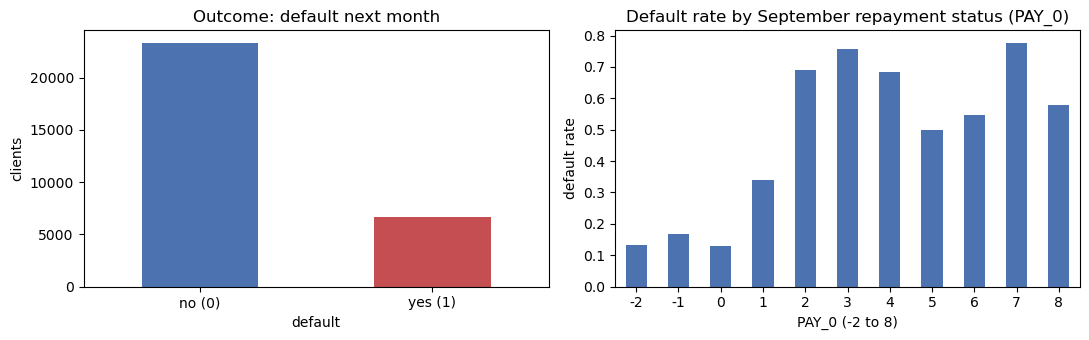

In [22]:
# undocumented codes: EDUCATION 0/5/6, MARRIAGE 0, and PAY_x -2/0 are not in the data dictionary
#PAY_x assumes -2 means the card wasn't used and 0 means the client paid the minimum and carried a balance
for col in ["EDUCATION", "MARRIAGE", "PAY_0", "PAY_2"]:
    print(f"{col:10s}", dict(sorted(X_raw[col].value_counts().items())))

#how similar each month's bill is to the next month's bill (1 = perfect correlation)
bills = X_raw.filter(like="BILL_AMT")
print("\ncorrelation between consecutive monthly bills:", np.diag(bills.corr().values, 1).round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
y.value_counts().sort_index().plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"])
ax[0].set(title="Outcome: default next month", xticklabels=["no (0)", "yes (1)"], ylabel="clients")
ax[0].tick_params(axis="x", rotation=0)
y.groupby(X_raw["PAY_0"]).mean().plot.bar(ax=ax[1], color="#4C72B0")        # default rate per September status
ax[1].set(title="Default rate by September repayment status (PAY_0)", xlabel="PAY_0 (-2 to 8)", ylabel="default rate")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**What the data currently shows**

- **22.1% of clients defaulted**, so always predicting "no default" is already **77.9%
  accurate**. Accuracy alone will flatter every model.
- **The coding does not match the data dictionary.** `EDUCATION` has undocumented codes 0, 5
  and 6 (345 rows) and `MARRIAGE` has 0 (54 rows). The repayment status also uses -2 and 0,
  which are undocumented. Codes -2, -1 and 0 all mean the client was not late, and their
  default rates (13%, 17%, 13%) are not in order, so `PAY_x` is not a clean scale.
- **The months are coded inconsistently.** `PAY_2` has only 28 clients coded "1 month late",
  against 3,688 in `PAY_0`.
- **Consecutive monthly bills correlate at 0.92 to 0.95**, which matters for Naive Bayes.
- **September repayment status dominates.** Clients 2 or more months late defaulted 50% to 78%
  of the time, against 13% to 17% for clients who were not late.

## 2. Statistical ML Models chosen

| Model | How it works | Why it fits this problem | Expected weakness |
|---|---|---|---|
| **Random forest** | Averages hundreds of decision trees, each grown on a bootstrap sample with a random subset of features at every split (bagging) | Handles the non-ordinal repayment codes, skewed amounts and interactions with no preprocessing | Less interpretable than a single tree; impurity-based importances favour continuous features |
| **Support vector machine, RBF kernel** | Finds the boundary with the widest margin between the classes, after mapping the data into a kernel space | A genuinely different, margin-based view of the problem; captures non-linear boundaries | Needs scaled inputs; training slows sharply as rows grow; outputs a score, not a probability |
| **Gaussian Naive Bayes** | Applies Bayes' rule, assuming every feature is independent and normally distributed within each class | Very fast, no tuning beyond smoothing; a useful simple reference | The six monthly bills correlate at about 0.9, so the independence assumption is badly broken |

**Reference point.** Every result is read against a **majority-class reference** that always
predicts "no default". It is not a model, but it sets the accuracy floor.

**Excluded features.** `SEX` and `MARRIAGE` are protected characteristics in credit decisions
(for example under the US Equal Credit Opportunity Act [4]), so they are left out of every
model. `AGE` stays in as the dataset's documented risk factor. Setting `PROTECTED = []` below
puts them back.

## 3. Training process

1. **Clean.** Merge the undocumented `EDUCATION` codes (0, 5, 6) into "others" (4).
2. **Split.** 80/20 with scikit-learn's `train_test_split` [2], stratified on the outcome so both sets keep the
   22% default rate, and seeded with 20 so the split can be reused.
3. **Preprocess.** The random forest uses the raw features. The SVM and Naive Bayes get the
   money columns put through `arcsinh` (a log-like transform that keeps negative bills
   negative) and then standardised, with `EDUCATION` one-hot encoded.
4. **Tune.** 5-fold stratified cross-validation on the training set only, choosing settings by
   ROC-AUC, which does not depend on the 0.5 threshold or the class imbalance. The SVM is tuned
   on a stratified 5,000-row sample of the training set, because each RBF fit on the full
   training set takes too long to repeat 45 times.
5. **Fit and save.** Each model is refit on the full training set with its best settings and
   saved with `joblib`, together with the test-row index, so later assignments can reuse the
   exact models and split. The test set is used once, in section 4.

In [23]:
from sklearn.model_selection import train_test_split

PROTECTED = ["SEX", "MARRIAGE"]                                    # excluded from the features
X = X_raw.drop(columns=PROTECTED).copy()
X["EDUCATION"] = X["EDUCATION"].replace({0: 4, 5: 4, 6: 4})        # undocumented codes are replaced with 4 ("others")
if "MARRIAGE" in X:
    X["MARRIAGE"] = X["MARRIAGE"].replace({0: 3})                  # undocumented 0 -> 3 ("others")

MONEY = ["LIMIT_BAL"] + [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]
CAT   = [c for c in ["EDUCATION", "SEX", "MARRIAGE"] if c in X]
OTHER = [c for c in X.columns if c not in MONEY + CAT]             # AGE and the six PAY_x statuses

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)            
print(f"train {X_train.shape}  test {X_test.shape} | default rate train {y_train.mean():.3f}, test {y_test.mean():.3f}")
print(f"features used ({X.shape[1]}):", ", ".join(X.columns))

train (24000, 21)  test (6000, 21) | default rate train 0.221, test 0.221
features used (21): LIMIT_BAL, EDUCATION, AGE, PAY_0, PAY_2, PAY_3, PAY_4, PAY_5, PAY_6, BILL_AMT1, BILL_AMT2, BILL_AMT3, BILL_AMT4, BILL_AMT5, BILL_AMT6, PAY_AMT1, PAY_AMT2, PAY_AMT3, PAY_AMT4, PAY_AMT5, PAY_AMT6


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.base import clone
import time

# SVM and Naive Bayes need comparable, roughly symmetric inputs; trees do not
scaled = ColumnTransformer([
    ("money", Pipeline([("asinh", FunctionTransformer(np.arcsinh)),     # log-like money columns to keep sign of negative bills too
                        ("scale", StandardScaler())]), MONEY),
    ("other", StandardScaler(), OTHER),
    ("cat",   OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=5000,
                                      stratify=y_train, random_state=SEED)   # SVM tuning sample for later

candidates = {   
    "Random forest": (RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
                      {"max_depth": [8, 16, None], "min_samples_leaf": [1, 10]}, (X_train, y_train)),
    "SVM (RBF)":     (Pipeline([("prep", scaled), ("m", SVC(kernel="rbf"))]),
                      {"m__C": [0.1, 1, 10], "m__gamma": ["scale", 0.01, 0.1]}, (X_sub, y_sub)),
    "Naive Bayes":   (Pipeline([("prep", scaled), ("m", GaussianNB())]),
                      {"m__var_smoothing": [1e-9, 1e-6, 1e-3, 1e-1]}, (X_train, y_train)),
}

searches, rows = {}, []
for name, (est, grid, (Xt, yt)) in candidates.items():
    t0 = time.time()
    gs = GridSearchCV(est, grid, cv=cv, scoring={"roc_auc": "roc_auc", "accuracy": "accuracy"},
                      refit="roc_auc").fit(Xt, yt)                    # every setting scored on all 5 folds
    searches[name] = gs
    i = gs.best_index_
    rows.append({"model": name, "tuned on": f"{len(Xt):,} rows",
                 "best settings": {k.replace("m__", ""): v for k, v in gs.best_params_.items()},
                 "CV ROC-AUC": f"{gs.cv_results_['mean_test_roc_auc'][i]:.3f} ± {gs.cv_results_['std_test_roc_auc'][i]:.3f}",
                 "CV accuracy": f"{gs.cv_results_['mean_test_accuracy'][i]:.3f} ± {gs.cv_results_['std_test_accuracy'][i]:.3f}",
                 "seconds": round(time.time() - t0)})
pd.DataFrame(rows).set_index("model")

,tuned on,best settings,CV ROC-AUC,CV accuracy,seconds
model,,,,,
Random forest,"24,000 rows","{'max_depth': 16, 'min_samples_leaf': 10}",0.784 ± 0.011,0.819 ± 0.003,55
SVM (RBF),"5,000 rows","{'C': 10, 'gamma': 0.01}",0.754 ± 0.018,0.816 ± 0.009,22
Naive Bayes,"24,000 rows",{'var_smoothing': 0.001},0.750 ± 0.005,0.757 ± 0.005,1


**Tuning result.** The random forest has the best cross-validated ROC-AUC (0.784) and
accuracy (0.819), with trees limited to depth 16 and at least 10 clients per leaf, which keeps
them from memorising individual clients. The SVM settled on C = 10 and gamma = 0.01, and Naive
Bayes needed more smoothing (0.001) than the default. The spread across folds is small (at most
±0.018 ROC-AUC), so the ranking is stable. Naive Bayes's cross-validated accuracy (0.757) is
already below the 77.9% floor.

In [25]:
import joblib, pathlib

#3 final models on its best parameters, refit on the full training set so we can save these models
final = {}
for name, gs in searches.items():
    final[name] = clone(gs.estimator).set_params(**gs.best_params_).fit(X_train, y_train)   # refit on full training set

out = pathlib.Path("models"); out.mkdir(exist_ok=True)
for name, model in final.items():
    joblib.dump(model, out / (name.split(" (")[0].lower().replace(" ", "_") + ".joblib"), compress=3)
pd.Series(X_test.index, name="test_row").to_csv(out / "test_index.csv", index=False)   # the exact test rows
print("saved:", ", ".join(sorted(p.name for p in out.iterdir())))

saved: naive_bayes.joblib, random_forest.joblib, svm.joblib, test_index.csv


## 4. Evaluation

### Quantitative

Accuracy is the brief's headline metric, but with 22% defaults it rewards predicting "no
default". So each model is also scored on precision and recall for defaulters (the class a
lender cares about), F1, and ROC-AUC (how well it ranks defaulters above non-defaulters,
whatever the threshold). All predictions use the default 0.5 threshold.

In [26]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)

def score(model):   # a continuous score for ROC-AUC: probability, or the SVM's distance from the margin
    return model.decision_function(X_test) if hasattr(model, "decision_function") else model.predict_proba(X_test)[:, 1]

ref = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)     # always predicts "no default" (baseline model)
pred = {name: m.predict(X_test) for name, m in final.items()}

table = pd.DataFrame({name: {
    "accuracy":  accuracy_score(y_test, p),
    "precision": precision_score(y_test, p, zero_division=0),
    "recall":    recall_score(y_test, p),
    "F1":        f1_score(y_test, p, zero_division=0),
    "ROC-AUC":   roc_auc_score(y_test, s)}
    for name, p, s in [("Majority-class reference", ref.predict(X_test), np.zeros(len(y_test)))]
                     + [(n, pred[n], score(m)) for n, m in final.items()]}).T
table.round(3)

,accuracy,precision,recall,F1,ROC-AUC
Majority-class reference,0.779,0.000,0.000,0.000,0.500
Random forest,0.821,0.681,0.356,0.467,0.771
SVM (RBF),0.817,0.684,0.320,0.436,0.702
Naive Bayes,0.754,0.451,0.523,0.484,0.736


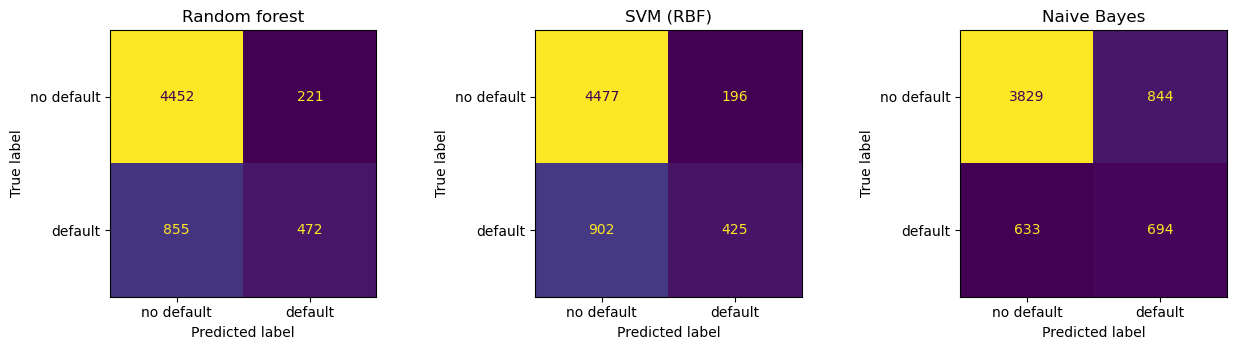

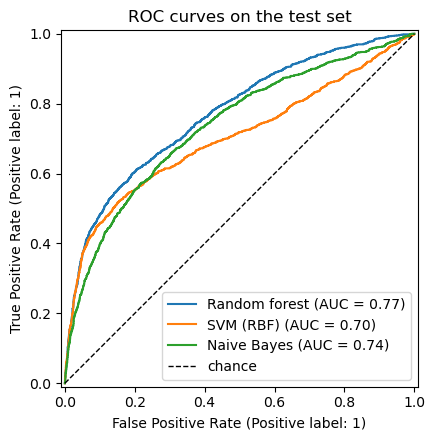

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (name, p) in zip(axes, pred.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, p, ax=ax, colorbar=False,
                                            display_labels=["no default", "default"])
    ax.set_title(name)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
for name, m in final.items():
    RocCurveDisplay.from_predictions(y_test, score(m), name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="chance")
ax.set_title("ROC curves on the test set"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

In [28]:
from itertools import combinations
from statsmodels.stats.contingency_tables import mcnemar

# McNemar's test: do two models make different numbers of mistakes on the same test clients? 
rows = []
for a, b in combinations(pred, 2):
    ca, cb = pred[a] == y_test.values, pred[b] == y_test.values
    res = mcnemar([[(ca & cb).sum(), (ca & ~cb).sum()],
                   [(~ca & cb).sum(), (~ca & ~cb).sum()]], exact=False, correction=True)
    rows.append({"pair": f"{a} vs {b}", "only first right": int((ca & ~cb).sum()),
                 "only second right": int((~ca & cb).sum()), "p-value": res.pvalue})
pd.DataFrame(rows).set_index("pair").style.format({"p-value": "{:.2g}"})

,only first right,only second right,p-value
pair,,,
Random forest vs SVM (RBF),88,66,0.091
Random forest vs Naive Bayes,738,337,3.1e-34
SVM (RBF) vs Naive Bayes,772,393,1.7e-28


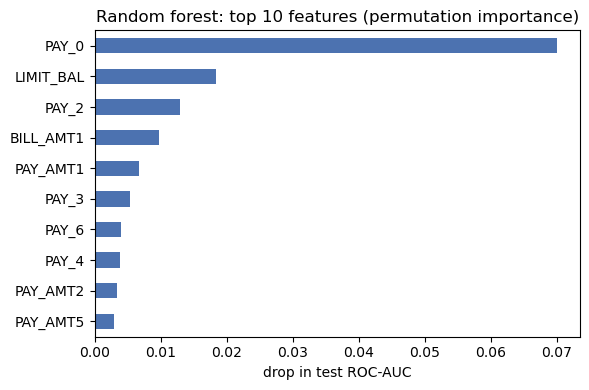

In [29]:
from sklearn.inspection import permutation_importance

# permutation importance: drop in test ROC-AUC when one feature is shuffled (fairer than impurity importance)
pi = permutation_importance(final["Random forest"], X_test, y_test, scoring="roc_auc",
                            n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values().tail(10)
ax = imp.plot.barh(figsize=(6, 4), color="#4C72B0")
ax.set(title="Random forest: top 10 features (permutation importance)", xlabel="drop in test ROC-AUC")
plt.tight_layout(); plt.show()

**Result**

- **The random forest is the best model overall**, with the highest accuracy (0.821) and the
  best ranking (ROC-AUC 0.771). It still misses 64% of defaulters (recall 0.356), because at the
  0.5 threshold it only flags clients it is fairly sure about.
- **The SVM is statistically tied with the random forest on accuracy** (0.817; McNemar's test [3],
  p = 0.09, with 88 against 66 clients that only one of them gets right), but it ranks clients
  worse (ROC-AUC 0.702 on test, against 0.754 in cross-validation). The likely cause is that
  C and gamma were tuned on a 5,000-row sample and do not carry over perfectly to the
  24,000-row fit. (tuning it on all 24,000 rows would likely help, at a much higher compute cost)
- **Naive Bayes is the only model below the accuracy floor** (0.754 against 0.779), and it is
  significantly less accurate than both others (p < 1e-27). Yet it catches the most defaulters
  (recall 0.523, best F1 0.484), because it flags far more clients: 1,538, against 693 for the
  random forest. Its probabilities are extreme (1.00 and 0.05 in the examples below), the usual
  symptom of counting correlated features as independent evidence.
- **One feature drives the forest.** Shuffling `PAY_0` cuts test ROC-AUC by about 0.07; no
  other feature costs more than 0.02. `AGE` is not in the top 10.

### Qualitative: specific clients

Four test clients, one from each pattern of agreement between the models. `P(default)` is the
predicted probability; the SVM gives a margin score instead (positive means "default").

In [30]:
rf, sv, nb = (pred[n] for n in final)
actual = y_test.values
cases = {
    "all three catch a defaulter":    (actual == 1) & (rf == 1) & (sv == 1) & (nb == 1),
    "all three miss a defaulter":     (actual == 1) & (rf == 0) & (sv == 0) & (nb == 0),
    "all three flag a non-defaulter": (actual == 0) & (rf == 1) & (sv == 1) & (nb == 1),
    "only Naive Bayes flags":         (nb == 1) & (rf == 0) & (sv == 0),
}
print({label: int(mask.sum()) for label, mask in cases.items()})       # how common each pattern is

cols = ["LIMIT_BAL", "AGE", "PAY_0", "PAY_2", "PAY_3", "BILL_AMT1", "PAY_AMT1"]
view = X_test[cols].assign(
    actual=actual,
    **{"RF P(default)": final["Random forest"].predict_proba(X_test)[:, 1].round(2),
       "SVM score":     final["SVM (RBF)"].decision_function(X_test).round(2),
       "NB P(default)": final["Naive Bayes"].predict_proba(X_test)[:, 1].round(2)})
#take first client from each group as an example
pd.concat([view[mask].head(1).assign(case=label) for label, mask in cases.items()]).set_index("case")

{'all three catch a defaulter': 329, 'all three miss a defaulter': 553, 'all three flag a non-defaulter': 138, 'only Naive Bayes flags': 930}


,LIMIT_BAL,AGE,PAY_0,PAY_2,PAY_3,BILL_AMT1,PAY_AMT1,actual,RF P(default),SVM score,NB P(default)
case,,,,,,,,,,,
all three catch a defaulter,300000,40,-1,3,2,5130,0,1,0.64,0.56,1.00
all three miss a defaulter,240000,48,0,-1,-1,3972,783,1,0.11,-1.05,0.05
all three flag a non-defaulter,360000,34,2,2,-2,2500,0,0,0.70,0.21,1.00
only Naive Bayes flags,200000,36,-2,-2,-2,0,0,1,0.27,-1.00,0.89


**What the examples show**

- **Caught by all three (329 test clients).** This client was 3 months late in August and 2 in
  July and paid nothing in September. Recent lateness is the signal every model picks up.
- **Missed by all three (553 clients, 42% of the 1,327 test defaulters).** This client paid on
  time in July and August, carried a small balance and made a payment, so nothing in the
  repayment history warns of default. These are the hardest cases, and they are a large share
  of all defaulters.
- **Flagged by all three, but did not default (138 clients).** Two months late in both August
  and September and paying nothing, a profile that defaults about 70% of the time. Flagging
  was reasonable; the clients who recover anyway are what limits precision.
- **Flagged only by Naive Bayes (930 clients).** No card use for three months and a zero
  balance. Naive Bayes gives 0.89 where the forest gives 0.27. This client did default, but only
  278 of the 930 (30%) did, which is why Naive Bayes ends up below the accuracy floor.

## 5. Discussion

**Comparing the three.** The random forest wins on both accuracy and ranking, and the SVM is
statistically tied with it on accuracy. Both get their accuracy by being cautious: they flag
620 to 690 of the 6,000 test clients and miss about two thirds of defaulters. Naive Bayes makes
the opposite trade, flagging more than twice as many clients to catch half of the defaulters,
and falls below the "always say no" floor as a result. On accuracy, the
random forest is the best model. In practice the choice depends on what a missed defaulter
costs a lender compared with an unnecessary review.

**How much the models add.** The best accuracy, 0.821, is only 4.2 points above the 77.9%
floor, and 553 defaulters are missed by every model. Most of the signal sits in the latest
repayment status. 

**Limitations**

- **All results use the 0.5 threshold.** Lowering it would trade accuracy for recall, which a
  lender may prefer. That threshold should be chosen on validation folds, not the test set.
- **The SVM was tuned on a 5,000-row sample**, which probably explains its weaker test ranking.
  Its scores are margins, not probabilities.
- **Naive Bayes's independence assumption is badly broken** by the correlated monthly bills and
  repayment statuses.
- **The features carry limited signal**
- **The repayment-status codes are inconsistent across months** and "are treated as numbers" here. We also had undocumented figures in features which we had to assume as "others" without clarification.

## References

1. Yeh, I.-C. (2009). *Default of credit card clients* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H
2. Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830. https://www.jmlr.org/papers/v12/pedregosa11a.html
3. Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10(7), 1895-1923. https://doi.org/10.1162/089976698300017197
4. Equal Credit Opportunity Act, 15 U.S.C. § 1691. https://www.law.cornell.edu/uscode/text/15/1691